# SEPSIS PREDICTION USING MACHINE LEARNING

In [1]:
#sepsis| model- classifyinto by clinical measures & patient-related features| dataset- origin, includes-variables, data preprocessing | 
# algorithm - develop prediction model, performance evaluated, highly imbalanced, 
# treshold- examine trade-off between detecting +ve and generating x alarms.| stremlit- accepts cinical features and display| demonstrates
#It is intended for academic research and demonstration and is not a clinically validated diagnostic system.

In [2]:
# feasibility: dataset, python- libs, LGBM, streamlit, economical, academic.

In [3]:
# complexity: moderately- DA and ML, large dataset, missing values, class imbalance. lgbm -train and evaluate, Suitable Tresh
#             streamlit- integrating the model c UF interface

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

In [5]:
df = pd.read_csv("Dataset.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1552210
Number of columns: 44


In [6]:
df.head()

,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1552210 entries, 0 to 1552209
Data columns (total 44 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   Unnamed: 0        1552210 non-null  int64  
 1   Hour              1552210 non-null  int64  
 2   HR                1398811 non-null  float64
 3   O2Sat             1349474 non-null  float64
 4   Temp              525226 non-null   float64
 5   SBP               1325945 non-null  float64
 6   MAP               1358940 non-null  float64
 7   DBP               1065656 non-null  float64
 8   Resp              1313875 non-null  float64
 9   EtCO2             57636 non-null    float64
 10  BaseExcess        84145 non-null    float64
 11  HCO3              65028 non-null    float64
 12  FiO2              129365 non-null   float64
 13  pH                107573 non-null   float64
 14  PaCO2             86301 non-null    float64
 15  SaO2              53561 non-null    float64
 16  

In [8]:
missing_count = df.isnull().sum()

print(missing_count)


Unnamed: 0                0
Hour                      0
HR                   153399
O2Sat                202736
Temp                1026984
SBP                  226265
MAP                  193270
DBP                  486554
Resp                 238335
EtCO2               1494574
BaseExcess          1468065
HCO3                1487182
FiO2                1422845
pH                  1444637
PaCO2               1465909
SaO2                1498649
AST                 1527027
BUN                 1445642
Alkalinephos        1527269
Calcium             1460879
Chloride            1481744
Creatinine          1457594
Bilirubin_direct    1549220
Glucose             1286694
Lactate             1510764
Magnesium           1454259
Phosphate           1489909
Potassium           1407685
Bilirubin_total     1529069
TroponinI           1537429
Hct                 1414777
Hgb                 1437619
PTT                 1506511
WBC                 1452763
Fibrinogen          1541968
Platelets           

In [9]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary.round(2)


,Missing Values,Missing Percentage
Bilirubin_direct,1549220,99.81
Fibrinogen,1541968,99.34
TroponinI,1537429,99.05
Bilirubin_total,1529069,98.51
Alkalinephos,1527269,98.39
AST,1527027,98.38
Lactate,1510764,97.33
PTT,1506511,97.06
SaO2,1498649,96.55
EtCO2,1494574,96.29


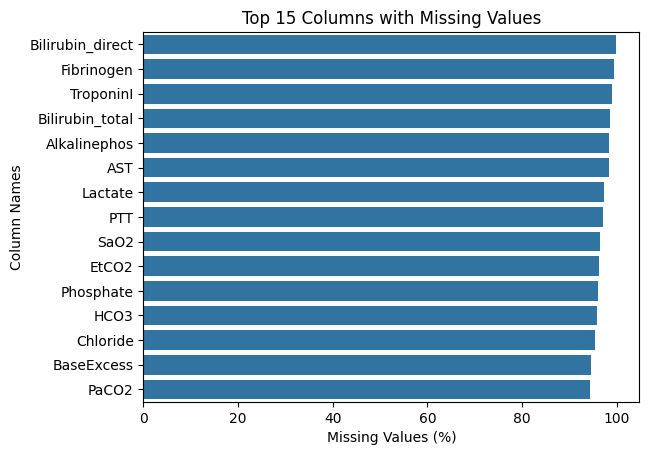

In [10]:
top_missing = missing_summary.head(15)

sns.barplot(
    x=top_missing["Missing Percentage"],
    y=top_missing.index
)

plt.title("Top 15 Columns with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Names")
plt.show()

In [11]:
print(df["SepsisLabel"].value_counts())
label_percent = df["SepsisLabel"].value_counts(normalize=True) * 100

print(label_percent.round(2))

SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64
SepsisLabel
0    98.2
1     1.8
Name: proportion, dtype: float64


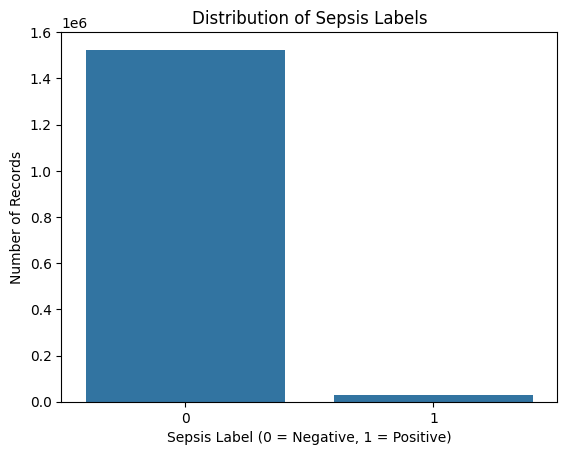

In [12]:
sns.countplot(data=df, x="SepsisLabel")

plt.title("Distribution of Sepsis Labels")
plt.xlabel("Sepsis Label (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")

plt.show()

In [13]:
print("Total records:", len(df))
print("Unique patients:", df["Patient_ID"].nunique())
print("Unique hours:", df["Hour"].nunique())

Total records: 1552210
Unique patients: 40336
Unique hours: 336


In [14]:
# Display the first 10 records for one patient
patient_id = df["Patient_ID"].iloc[0]

df[df["Patient_ID"] == patient_id].head(10)


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072
5,5,5,62.0,100.0,NaN,124.0,85.0,61.0,14.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,6,0,17072
6,6,6,61.0,100.0,NaN,101.0,75.0,58.0,14.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,7,0,17072
7,7,7,68.0,100.0,35.78,142.0,93.5,78.0,16.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,8,0,17072
8,8,8,71.0,100.0,NaN,121.0,74.0,91.0,14.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,9,0,17072
9,9,9,69.0,100.0,NaN,120.0,79.0,98.0,14.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,10,0,17072


In [15]:
records_per_patient = df.groupby("Patient_ID").size()

print("Minimum records:", records_per_patient.min())
print("Maximum records:", records_per_patient.max())
print("Average records:", round(records_per_patient.mean(), 2))

Minimum records: 8
Maximum records: 336
Average records: 38.48


In [16]:
df.columns

Index(['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP',
       'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2',
       'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
       'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate',
       'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC',
       'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2',
       'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID'],
      dtype='object')

## EDA

In [17]:
df.describe().round(2)

,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
count,1552210.00,1552210.00,1398811.00,1349474.00,525226.00,1325945.00,1358940.00,1065656.00,1313875.00,57636.00,...,10242.00,92209.00,1552210.00,1552210.00,940250.0,940250.0,1552202.00,1552210.00,1552210.00,1552210.00
mean,25.49,25.49,84.58,97.19,36.98,123.75,82.40,63.83,18.73,32.96,...,287.39,196.01,62.01,0.56,0.5,0.5,-56.13,26.99,0.02,59201.48
std,28.88,28.88,17.33,2.94,0.77,23.23,16.34,13.96,5.10,7.95,...,153.00,103.64,16.39,0.50,0.5,0.5,162.26,29.01,0.13,50248.19
min,0.00,0.00,20.00,20.00,20.90,20.00,20.00,20.00,1.00,10.00,...,34.00,1.00,14.00,0.00,0.0,0.0,-5366.86,1.00,0.00,1.00
25%,9.00,9.00,72.00,96.00,36.50,107.00,71.00,54.00,15.00,28.00,...,184.00,126.00,51.68,0.00,0.0,0.0,-47.05,11.00,0.00,9990.00
50%,19.00,19.00,83.50,98.00,37.00,121.00,80.00,62.00,18.00,33.00,...,250.00,181.00,64.00,1.00,0.0,1.0,-6.03,21.00,0.00,19965.00
75%,33.00,33.00,95.50,99.50,37.50,138.00,92.00,72.00,21.50,38.00,...,349.00,244.00,74.00,1.00,1.0,1.0,-0.04,34.00,0.00,109878.00
max,335.00,335.00,280.00,100.00,50.00,300.00,300.00,300.00,100.00,100.00,...,1760.00,2322.00,100.00,1.00,1.0,1.0,23.99,336.00,1.00,120000.00


In [18]:
vital_columns = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]

df[vital_columns].describe().round(2)

,HR,O2Sat,Temp,SBP,MAP,Resp
count,1398811.00,1349474.00,525226.00,1325945.00,1358940.00,1313875.00
mean,84.58,97.19,36.98,123.75,82.40,18.73
std,17.33,2.94,0.77,23.23,16.34,5.10
min,20.00,20.00,20.90,20.00,20.00,1.00
25%,72.00,96.00,36.50,107.00,71.00,15.00
50%,83.50,98.00,37.00,121.00,80.00,18.00
75%,95.50,99.50,37.50,138.00,92.00,21.50
max,280.00,100.00,50.00,300.00,300.00,100.00


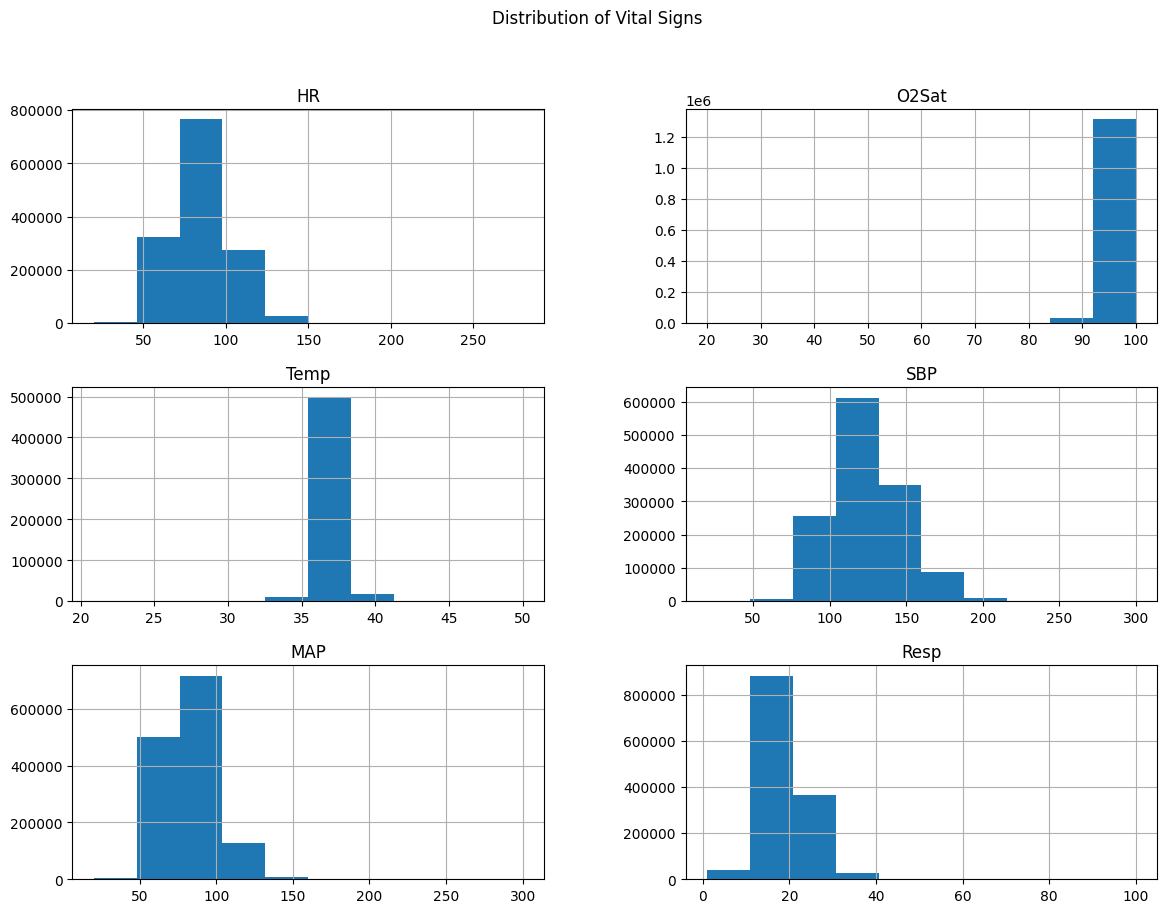

In [19]:
df[vital_columns].hist(
    figsize=(14, 10),
)

plt.suptitle("Distribution of Vital Signs")
plt.show()

In [20]:
df.groupby("SepsisLabel")[vital_columns].median().round(2)


,HR,O2Sat,Temp,SBP,MAP,Resp
SepsisLabel,,,,,,
0,83.0,98.0,37.0,121.0,80.0,18.0
1,90.0,98.0,37.3,118.0,78.0,20.0


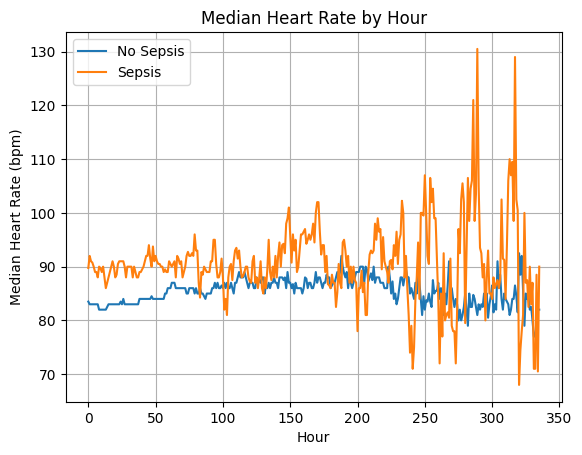

In [21]:
for label in [0, 1]:
    subset = df[df["SepsisLabel"] == label]

    hourly_hr = subset.groupby("Hour")["HR"].median()

    plt.plot(
        hourly_hr.index,
        hourly_hr.values,
        label=f"SepsisLabel = {label}"
    )

plt.title("Median Heart Rate by Hour")
plt.xlabel("Hour")
plt.ylabel("Median Heart Rate (bpm)")
plt.legend(["No Sepsis", "Sepsis"])
plt.grid(True)
plt.show()

In [22]:
### Missing values

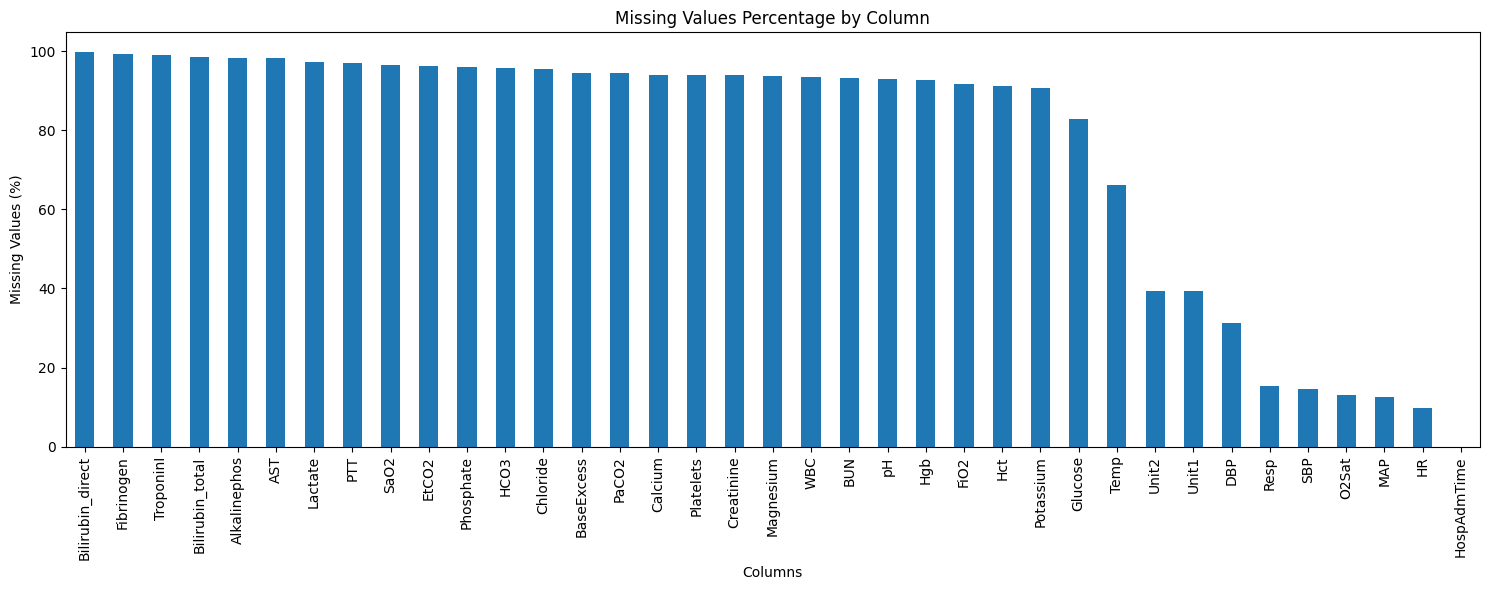

In [23]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent.sort_values(ascending=False)

missing_percent[missing_percent > 0].plot(
    kind="bar",
    figsize=(15, 6)
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [24]:
vital_columns = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]

missing_by_sepsis = (
    df.groupby("SepsisLabel")[vital_columns]
    .apply(lambda group: group.isnull().mean() * 100)
    .T
)

missing_by_sepsis.columns = ["No Sepsis (%)", "Sepsis (%)"]

missing_by_sepsis.round(2)

,No Sepsis (%),Sepsis (%)
HR,9.92,7.94
O2Sat,13.11,10.36
Temp,66.16,66.06
SBP,14.57,15.20
MAP,12.51,9.50
Resp,15.37,14.34


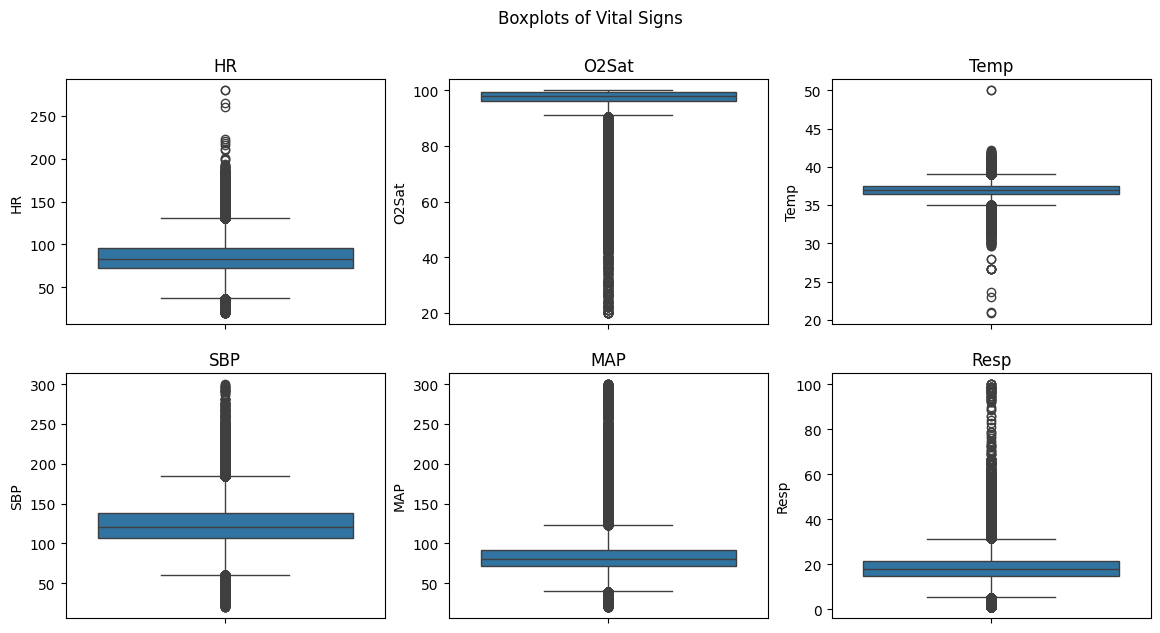

In [25]:
vital_columns = ["HR", "O2Sat", "Temp", "SBP", "MAP","Resp"]

plt.figure(figsize=(14, 7))

for i, column in enumerate(vital_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.suptitle("Boxplots of Vital Signs")
plt.show()

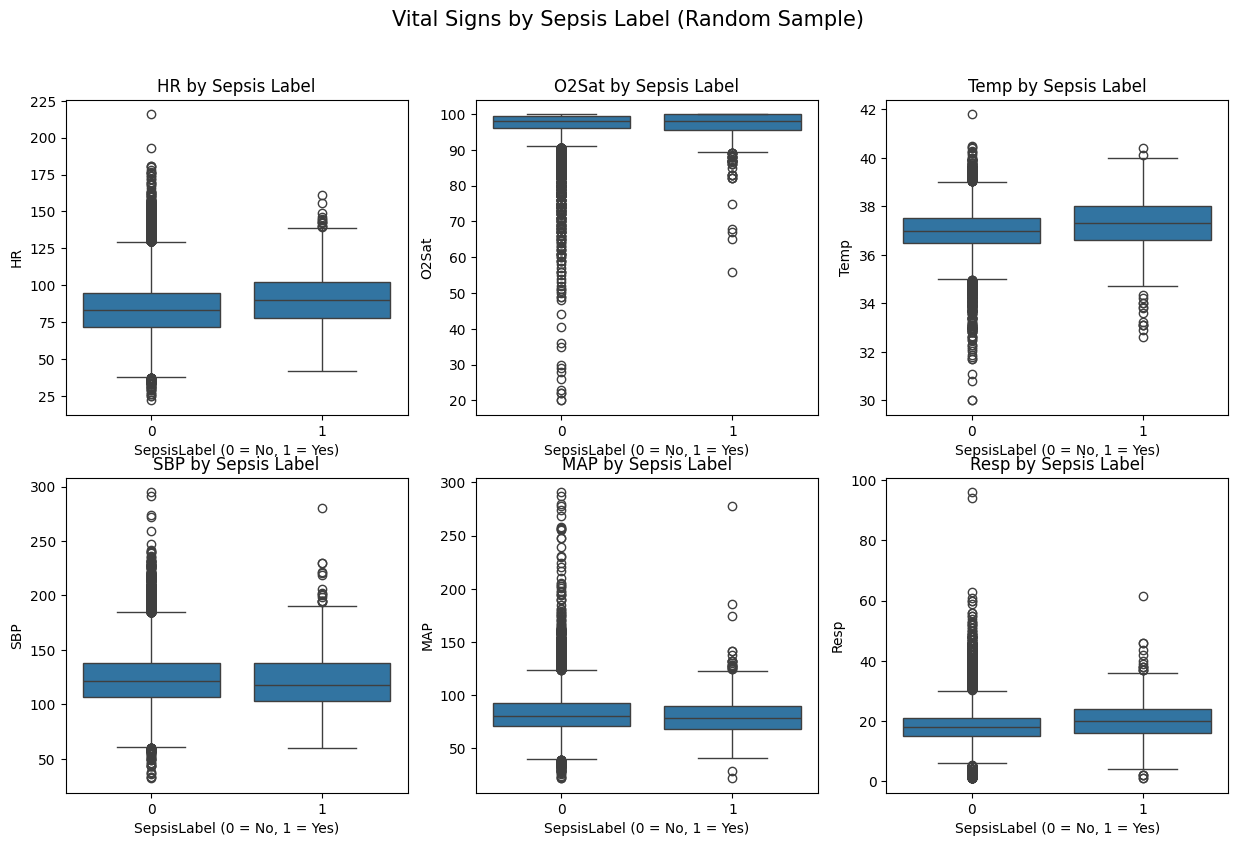

In [26]:
vital_columns = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]

sample_df = df.sample(
    n=min(100000, len(df)),
    random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for column, ax in zip(vital_columns, axes.flatten()):
    sns.boxplot(
        data=sample_df,
        x="SepsisLabel",
        y=column,
        ax=ax
    )
    ax.set_title(f"{column} by Sepsis Label")
    ax.set_xlabel("SepsisLabel (0 = No, 1 = Yes)")

plt.suptitle("Vital Signs by Sepsis Label (Random Sample)", fontsize=15)
plt.show()

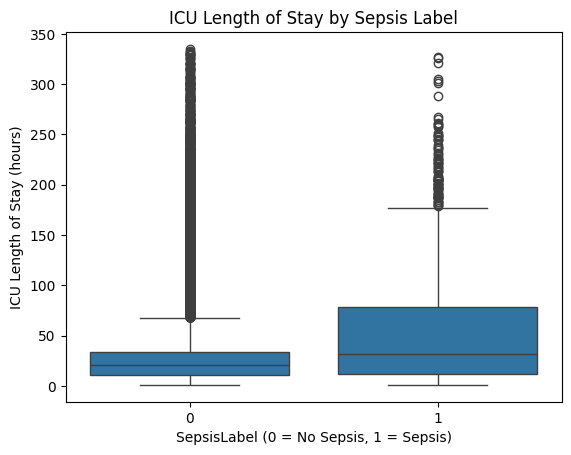

In [27]:
sns.boxplot(
    data=df.sample(n=min(100000, len(df)), random_state=42),
    x="SepsisLabel",
    y="ICULOS"
)

plt.title("ICU Length of Stay by Sepsis Label")
plt.xlabel("SepsisLabel (0 = No Sepsis, 1 = Sepsis)")
plt.ylabel("ICU Length of Stay (hours)")
plt.show()

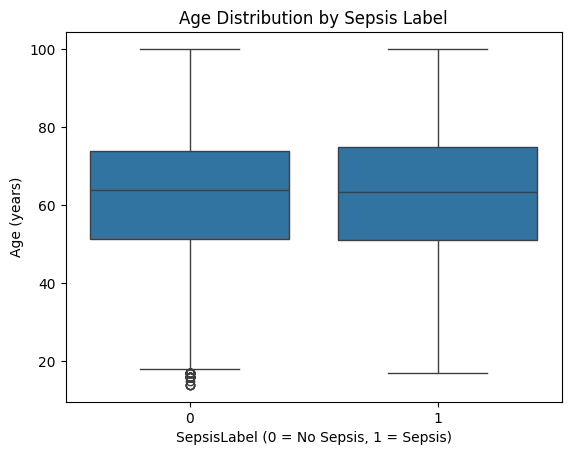

In [28]:
sns.boxplot(
    data=df.sample(n=min(100000, len(df)), random_state=42),
    x="SepsisLabel",
    y="Age"
)

plt.title("Age Distribution by Sepsis Label")
plt.xlabel("SepsisLabel (0 = No Sepsis, 1 = Sepsis)")
plt.ylabel("Age (years)")
plt.show()

In [29]:
# Gender Distribution by sepsis label
gender_summary = pd.crosstab(
    df["Gender"],
    df["SepsisLabel"],
    normalize="columns"
) * 100

gender_summary.round(2)

SepsisLabel,0,1
Gender,,
0,44.14,40.67
1,55.86,59.33


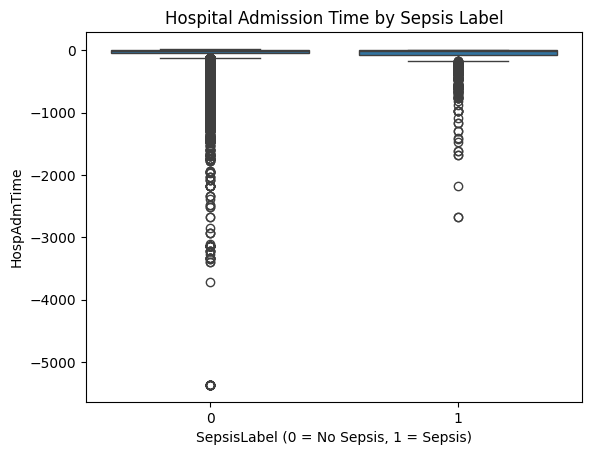

In [30]:
sns.boxplot(
    data=df.sample(n=min(100000, len(df)), random_state=42),
    x="SepsisLabel",
    y="HospAdmTime"
)

plt.title("Hospital Admission Time by Sepsis Label")
plt.xlabel("SepsisLabel (0 = No Sepsis, 1 = Sepsis)")
plt.ylabel("HospAdmTime")
plt.show()

In [31]:
## sepsis rates across age groups

age_bins = [0, 18, 40, 60, 80, 120]
age_labels = ["0–18", "19–40", "41–60", "61–80", "81+"]

df["AgeGroup_EDA"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)
sepsis_rate_by_age = (
    df.groupby("AgeGroup_EDA", observed=False)["SepsisLabel"]
    .mean()
    .mul(100)
    .round(2)
)

sepsis_rate_by_age

AgeGroup_EDA
0–18     1.84
19–40    1.78
41–60    1.81
61–80    1.81
81+      1.74
Name: SepsisLabel, dtype: float64

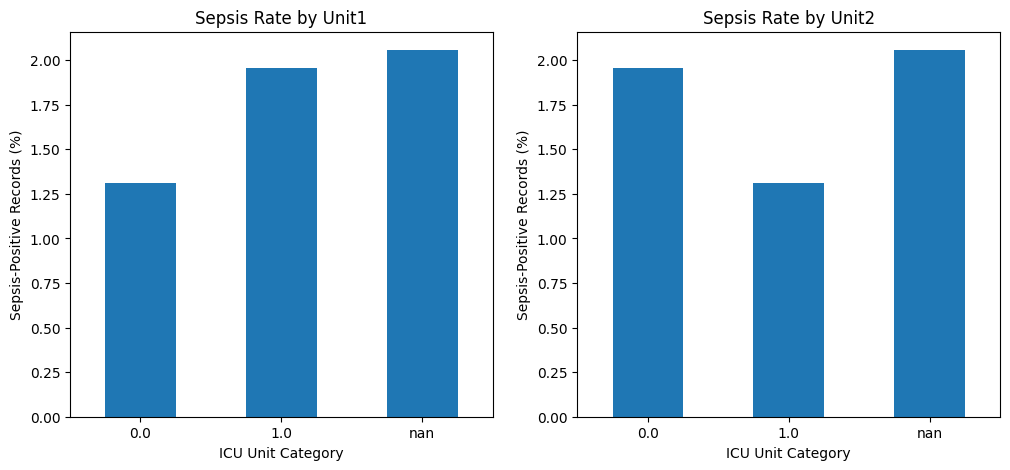

In [32]:
unit_columns = ["Unit1", "Unit2"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for column, ax in zip(unit_columns, axes):
    rates = (
        df.groupby(column, dropna=False)["SepsisLabel"]
        .mean()
        .mul(100)
    )

    rates.plot(kind="bar", ax=ax)
    ax.set_title(f"Sepsis Rate by {column}")
    ax.set_xlabel("ICU Unit Category")
    ax.set_ylabel("Sepsis-Positive Records (%)")
    ax.tick_params(axis="x", rotation=0)

plt.show()

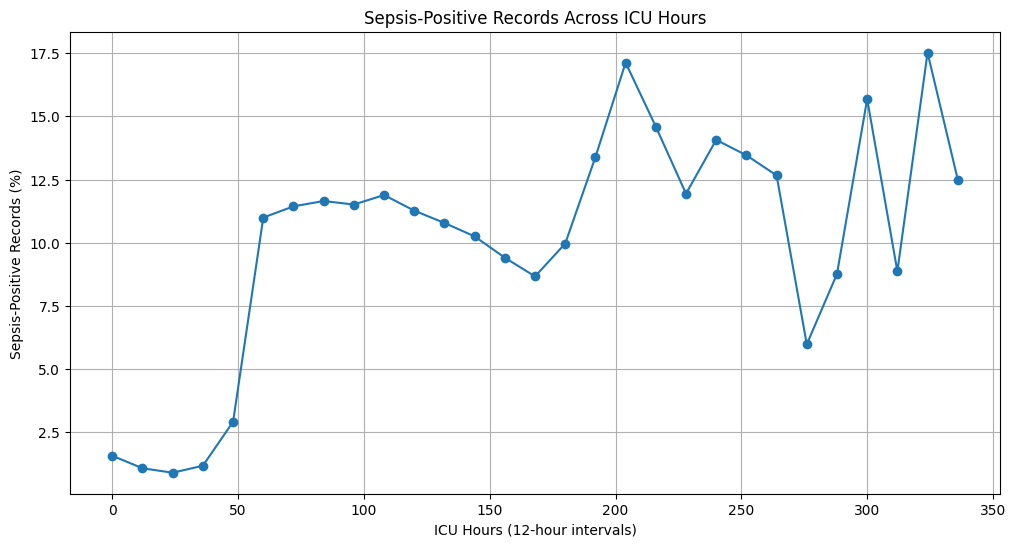

In [33]:
# Group ICU hours into 12-hour intervals
df["ICULOS_Group"] = (df["ICULOS"] // 12) * 12

# Calculate sepsis-positive record percentage in each interval
sepsis_by_iculos = (
    df.groupby("ICULOS_Group")["SepsisLabel"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(12, 6))
sepsis_by_iculos.plot(kind="line", marker="o")

plt.title("Sepsis-Positive Records Across ICU Hours")
plt.xlabel("ICU Hours (12-hour intervals)")
plt.ylabel("Sepsis-Positive Records (%)")
plt.grid(True)
plt.show()

In [34]:
## Compare sepsis-positive records across vital-sign ranges

HR_Group_EDA
<60        1.17
60–80      1.37
80–100     1.83
100–120    2.88
120–150    4.26
150+       4.57
Name: SepsisLabel, dtype: float64


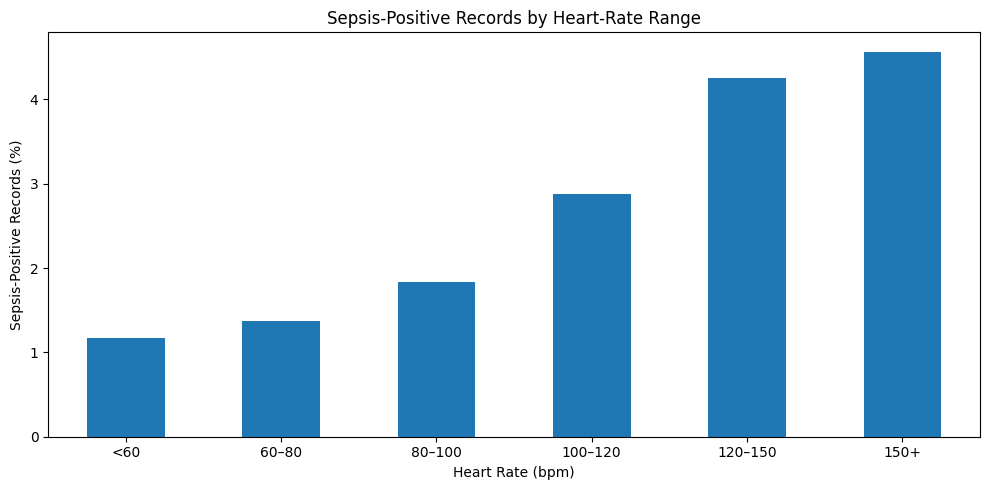

In [35]:
hr_bins = [0, 60, 80, 100, 120, 150, 250]
hr_labels = ["<60", "60–80", "80–100", "100–120", "120–150", "150+"]

df["HR_Group_EDA"] = pd.cut(
    df["HR"],
    bins=hr_bins,
    labels=hr_labels,
    include_lowest=True
)

sepsis_by_hr = (
    df.groupby("HR_Group_EDA", observed=False)["SepsisLabel"]
    .mean()
    .mul(100)
)

print(sepsis_by_hr.round(2))

sepsis_by_hr.plot(kind="bar", figsize=(10, 5))
plt.title("Sepsis-Positive Records by Heart-Rate Range")
plt.xlabel("Heart Rate (bpm)")
plt.ylabel("Sepsis-Positive Records (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                  count  Sepsis_Percentage
O2Sat_Group_EDA                           
Below 90          23908               3.28
90–94            164137               2.11
94–98            637725               1.70
98–100           523704               1.90


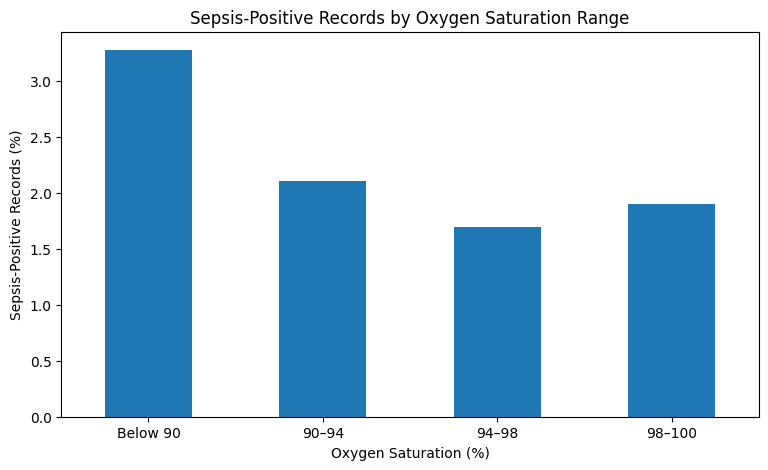

In [36]:
o2_bins = [0, 90, 94, 98, 100]
o2_labels = ["Below 90", "90–94", "94–98", "98–100"]

df["O2Sat_Group_EDA"] = pd.cut(
    df["O2Sat"],
    bins=o2_bins,
    labels=o2_labels,
    include_lowest=True
)

sepsis_by_o2 = (
    df.groupby("O2Sat_Group_EDA", observed=False)["SepsisLabel"]
    .agg(["mean", "count"])
)

sepsis_by_o2["Sepsis_Percentage"] = (
    sepsis_by_o2["mean"] * 100
).round(2)

print(sepsis_by_o2[["count", "Sepsis_Percentage"]])

sepsis_by_o2["Sepsis_Percentage"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sepsis-Positive Records by Oxygen Saturation Range")
plt.xlabel("Oxygen Saturation (%)")
plt.ylabel("Sepsis-Positive Records (%)")
plt.xticks(rotation=0)
plt.show()

In [37]:
## Correlation between vital signs

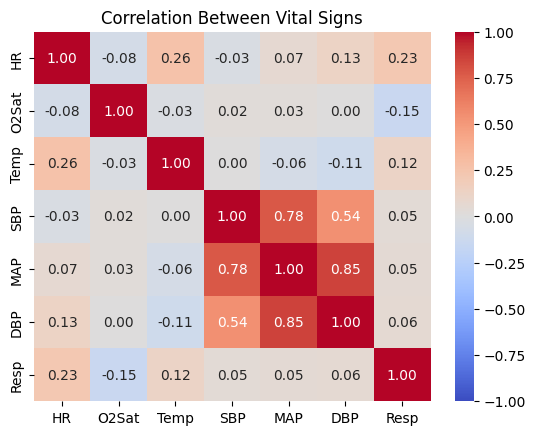

In [38]:
vital_signs = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]
correlation = df[vital_signs].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Vital Signs")
plt.show()

## DATA PRE-PROCESSING

In [39]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nTarget variable:")
print(df["SepsisLabel"].value_counts())

print("\nUnique patients:", df["Patient_ID"].nunique())

Dataset shape: (1552210, 48)

Column names:
Index(['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP',
       'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2',
       'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
       'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate',
       'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC',
       'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2',
       'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID', 'AgeGroup_EDA',
       'ICULOS_Group', 'HR_Group_EDA', 'O2Sat_Group_EDA'],
      dtype='object')

Target variable:
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64

Unique patients: 40336


In [40]:
eda_columns = ["AgeGroup_EDA", "ICULOS_Group", "HR_Group_EDA", "O2Sat_Group_EDA"]

df = df.drop(columns=eda_columns, errors="ignore")
df.columns

Index(['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP',
       'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2',
       'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
       'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate',
       'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC',
       'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2',
       'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID'],
      dtype='object')

In [41]:
print(df["Unnamed: 0"].equals(df["Hour"]))

True


In [42]:
df = df.drop("Unnamed: 0", axis=1)
df

,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1552205,21,83.0,99.0,NaN,121.0,77.0,54.0,22.0,NaN,NaN,...,NaN,NaN,88.00,0,1.0,0.0,-2.93,22,0,113911
1552206,22,80.0,92.0,NaN,102.0,73.0,51.0,24.0,NaN,NaN,...,NaN,NaN,88.00,0,1.0,0.0,-2.93,23,0,113911
1552207,23,95.0,97.0,36.7,128.5,83.0,58.5,25.0,NaN,NaN,...,NaN,NaN,88.00,0,1.0,0.0,-2.93,24,0,113911
1552208,24,104.0,99.0,NaN,127.0,85.0,59.0,24.0,NaN,NaN,...,NaN,NaN,88.00,0,1.0,0.0,-2.93,25,0,113911


In [43]:
vital_signs = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]

print("Missing values:")
print(df[vital_signs].isnull().sum())

print("\nMissing percentage:")
print((df[vital_signs].isnull().mean() * 100).round(2))

Missing values:
HR        153399
O2Sat     202736
Temp     1026984
SBP       226265
MAP       193270
DBP       486554
Resp      238335
dtype: int64

Missing percentage:
HR        9.88
O2Sat    13.06
Temp     66.16
SBP      14.58
MAP      12.45
DBP      31.35
Resp     15.35
dtype: float64


In [44]:
vital_signs = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]

print(df[vital_signs].agg(["min", "max"]).T)

        min    max
HR     20.0  280.0
O2Sat  20.0  100.0
Temp   20.9   50.0
SBP    20.0  300.0
MAP    20.0  300.0
DBP    20.0  300.0
Resp    1.0  100.0


In [45]:
limits = {
    "HR":    (30, 220),
    "O2Sat": (50, 100),
    "Temp":  (32, 42),
    "SBP":   (50, 250),
    "MAP":   (30, 180),
    "DBP":   (20, 150),
    "Resp":  (4, 60),
}

for col, (low, high) in limits.items():
    mask = (df[col] < low) | (df[col] > high)
    print(f"{col}: {mask.sum()} values set to NaN")
    df.loc[mask, col] = np.nan

HR: 137 values set to NaN
O2Sat: 272 values set to NaN
Temp: 117 values set to NaN
SBP: 382 values set to NaN
MAP: 876 values set to NaN
DBP: 374 values set to NaN
Resp: 1906 values set to NaN


In [46]:
vital_signs = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]

missing_after_cleaning = pd.DataFrame({
    "Missing_Count": df[vital_signs].isnull().sum(),
    "Missing_Percentage": (
        df[vital_signs].isnull().mean() * 100
    ).round(2)
})
print(missing_after_cleaning)

       Missing_Count  Missing_Percentage
HR            153536                9.89
O2Sat         203008               13.08
Temp         1027101               66.17
SBP           226647               14.60
MAP           194146               12.51
DBP           486928               31.37
Resp          240241               15.48


In [47]:
high_missing = df.columns[
    (df.isnull().mean() * 100) > 90
]

df = df.drop(columns=high_missing)

print(df.shape)

(1552210, 17)


In [48]:
df.columns

Index(['Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Glucose',
       'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS',
       'SepsisLabel', 'Patient_ID'],
      dtype='object')

In [49]:

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nUnique patients:", df["Patient_ID"].nunique())
print("\nTarget distribution:")
print(df["SepsisLabel"].value_counts())


Dataset shape: (1552210, 17)

Columns:
Index(['Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Glucose',
       'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS',
       'SepsisLabel', 'Patient_ID'],
      dtype='object')

Unique patients: 40336

Target distribution:
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64


In [50]:

feature_columns = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "Glucose", "Age", "Gender", "Unit1", "Unit2",
    "HospAdmTime", "ICULOS", "Hour"
]

target_column = "SepsisLabel"
patient_column = "Patient_ID"

model_df = df[
    feature_columns + [target_column, patient_column]
].copy()

print("Model dataset shape:", model_df.shape)
print("Number of patients:", model_df[patient_column].nunique())
print("\nMissing values:")
print(model_df[feature_columns].isnull().sum())


Model dataset shape: (1552210, 17)
Number of patients: 40336

Missing values:
HR              153536
O2Sat           203008
Temp           1027101
SBP             226647
MAP             194146
DBP             486928
Resp            240241
Glucose        1286694
Age                  0
Gender               0
Unit1           611960
Unit2           611960
HospAdmTime          8
ICULOS               0
Hour                 0
dtype: int64


## Model Building and Evaluation

In [51]:
from sklearn.model_selection import GroupShuffleSplit
import lightgbm as lgb
from sklearn.metrics import classification_report

In [52]:
X = model_df[feature_columns]
y = model_df[target_column]
groups = model_df[patient_column]

In [53]:
splitter = GroupShuffleSplit(n_splits=1,test_size=0.30,random_state=42)

In [54]:
train_idx, test_idx = next(splitter.split(X, y, groups))

In [55]:
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

In [56]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(
    "Patients in both sets:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)


Training records: 1087702
Testing records: 464508
Patients in both sets: 0


In [57]:
#filling missing values
features = X_train.columns

median_columns = [col for col in features
                  if col not in ["Unit1", "Unit2"]]

unit_columns = ["Unit1", "Unit2"]

medians = X_train[median_columns].median()
X_train[median_columns] = X_train[median_columns].fillna(medians)
X_test[median_columns] = X_test[median_columns].fillna(medians)


modes = X_train[unit_columns].mode().iloc[0]
X_train[unit_columns] = X_train[unit_columns].fillna(modes)
X_test[unit_columns] = X_test[unit_columns].fillna(modes)


print("Train missing:", X_train.isnull().sum().sum())
print("Test missing:", X_test.isnull().sum().sum())

Train missing: 0
Test missing: 0


In [58]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

In [59]:
model = lgb.LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42)
model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 19845, number of negative: 1067857
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021491 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2566
[LightGBM] [Info] Number of data points in the train set: 1087702, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.018245 -> initscore=-3.985457
[LightGBM] [Info] Start training from score -3.985457


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [60]:
y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred,target_names=["No Sepsis", "Sepsis"],zero_division=0))


              precision    recall  f1-score   support

   No Sepsis       0.99      0.77      0.87    456437
      Sepsis       0.05      0.64      0.09      8071

    accuracy                           0.77    464508
   macro avg       0.52      0.71      0.48    464508
weighted avg       0.98      0.77      0.85    464508



[[352028 104409]
 [  2870   5201]]


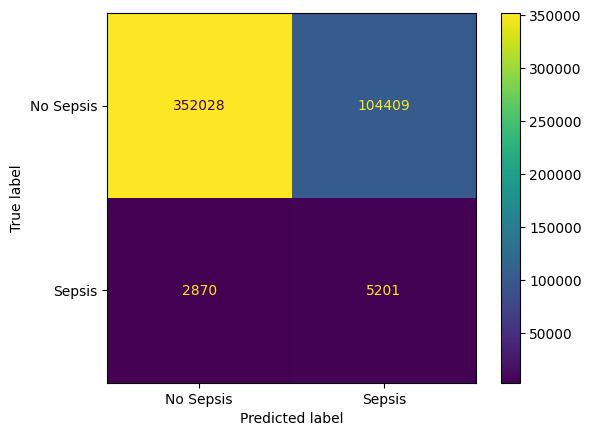

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Sepsis", "Sepsis"]
).plot(values_format="d")

plt.show()


In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.7690481111197224
Precision: 0.04745005017790348
Recall: 0.6444058976582827
F1 Score: 0.08839149905252335


In [63]:
# Get predicted probabilities for Sepsis
y_prob = model.predict_proba(X_test)[:, 1]

# Try a threshold of 0.7
y_pred_07 = (y_prob >= 0.7).astype(int)

print(classification_report(y_test,y_pred_07,target_names=["No Sepsis", "Sepsis"],zero_division=0))

              precision    recall  f1-score   support

   No Sepsis       0.99      0.93      0.96    456437
      Sepsis       0.09      0.41      0.15      8071

    accuracy                           0.92    464508
   macro avg       0.54      0.67      0.55    464508
weighted avg       0.97      0.92      0.94    464508



In [64]:
y_pred_03 = (y_prob >= 0.3).astype(int)

print(classification_report(y_test,y_pred_03,target_names=["No Sepsis", "Sepsis"],zero_division=0))

              precision    recall  f1-score   support

   No Sepsis       0.99      0.53      0.69    456437
      Sepsis       0.03      0.84      0.06      8071

    accuracy                           0.54    464508
   macro avg       0.51      0.68      0.38    464508
weighted avg       0.98      0.54      0.68    464508



In [65]:
results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

   Threshold  Precision  Recall  F1 Score
0        0.1      0.019   0.990     0.036
1        0.2      0.024   0.923     0.047
2        0.3      0.031   0.837     0.059
3        0.4      0.038   0.747     0.072
4        0.5      0.047   0.644     0.088
5        0.6      0.066   0.525     0.117
6        0.7      0.092   0.413     0.151
7        0.8      0.113   0.314     0.166
8        0.9      0.157   0.079     0.106


### Model Tuning

In [66]:
print(model.get_params())

{'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 100, 'n_jobs': None, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'scale_pos_weight': 53.809876543209874}


In [67]:
model_tuned = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbosity=-1
)

model_tuned.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,50


In [68]:
y_prob_tuned = model_tuned.predict_proba(X_test)[:, 1]

y_pred_tuned = (y_prob_tuned >= 0.5).astype(int)

print(classification_report(y_test,y_pred_tuned,target_names=["No Sepsis", "Sepsis"],zero_division=0))

              precision    recall  f1-score   support

   No Sepsis       0.99      0.81      0.89    456437
      Sepsis       0.05      0.62      0.10      8071

    accuracy                           0.81    464508
   macro avg       0.52      0.71      0.50    464508
weighted avg       0.98      0.81      0.88    464508



        Feature  Importance
8           Age        2120
12  HospAdmTime        2102
0            HR         726
13       ICULOS         682
14         Hour         506
5           DBP         442
6          Resp         428
2          Temp         413
3           SBP         405
4           MAP         335
1         O2Sat         287
10        Unit1         223
9        Gender         181
7       Glucose         150
11        Unit2           0


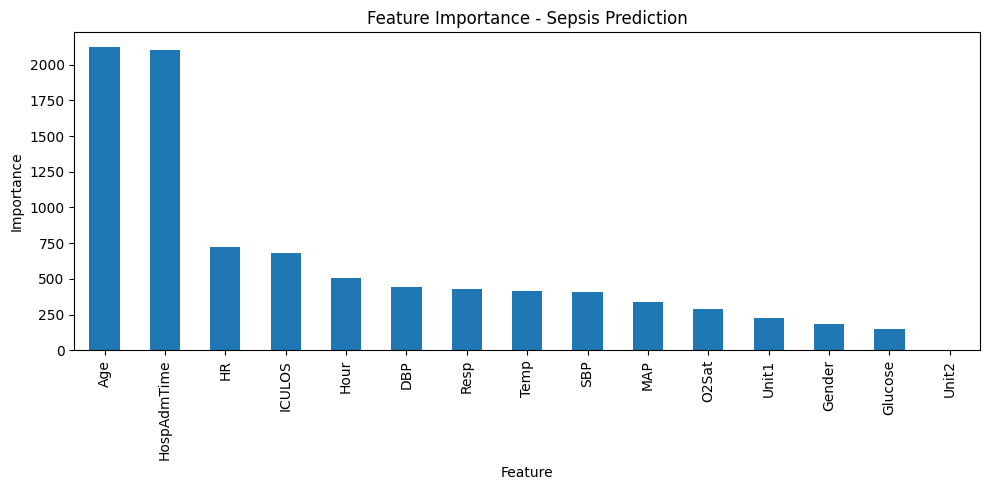

In [69]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_tuned.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Feature Importance - Sepsis Prediction")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [70]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))
print("PR-AUC:", average_precision_score(y_test, y_prob_tuned))

ROC-AUC: 0.7895222670583071
PR-AUC: 0.08779309006386672


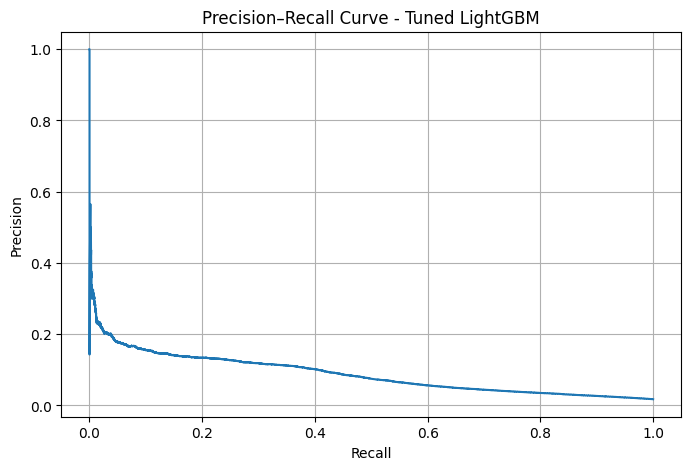

In [71]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob_tuned
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve - Tuned LightGBM")
plt.grid(True)
plt.show()

In [72]:
# Get patient IDs for the existing training records
train_groups = groups.iloc[train_idx]

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    splitter_val.split(X_train, y_train, groups=train_groups)
)

X_fit = X_train.iloc[fit_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_fit = y_train.iloc[fit_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Model training records:", len(X_fit))
print("Validation records:", len(X_val))
print(
    "Patients in both sets:",
    len(set(train_groups.iloc[fit_idx]) & set(train_groups.iloc[val_idx]))
)

Model training records: 871230
Validation records: 216472
Patients in both sets: 0


In [73]:
scale_pos_weight_val = (
    (y_fit == 0).sum() / (y_fit == 1).sum()
)

model_val = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    verbosity=-1
)

model_val.fit(X_fit, y_fit)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,50


In [74]:
# Predict sepsis probabilities
y_val_prob = model_val.predict_proba(X_val)[:, 1]

# Predict using threshold 0.5
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Evaluate the model
print(classification_report(y_val,y_val_pred,target_names=["No Sepsis", "Sepsis"],zero_division=0))

print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))
print("PR-AUC:", average_precision_score(y_val, y_val_prob))

              precision    recall  f1-score   support

   No Sepsis       0.99      0.82      0.90    212596
      Sepsis       0.05      0.55      0.10      3876

    accuracy                           0.82    216472
   macro avg       0.52      0.69      0.50    216472
weighted avg       0.97      0.82      0.88    216472

ROC-AUC: 0.7566715795931764
PR-AUC: 0.07675225697534493


In [75]:
results = []

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1 Score": f1_score(y_val, pred, zero_division=0)
    })

validation_results = pd.DataFrame(results)
print(validation_results.round(3))

   Threshold  Precision  Recall  F1 Score
0        0.3      0.031   0.794     0.060
1        0.4      0.041   0.673     0.076
2        0.5      0.053   0.549     0.097
3        0.6      0.072   0.443     0.124
4        0.7      0.098   0.350     0.153
5        0.8      0.118   0.255     0.161
6        0.9      0.154   0.069     0.095


In [76]:
# Predict probabilities on the untouched test set
y_test_prob_final = model_val.predict_proba(X_test)[:, 1]

# Use threshold selected from validation
final_threshold = 0.8
y_test_pred_final = (
    y_test_prob_final >= final_threshold
).astype(int)

print("Final threshold:", final_threshold)

print(classification_report(y_test, y_test_pred_final,target_names=["No Sepsis", "Sepsis"],zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_final))
print("PR-AUC:", average_precision_score(y_test, y_test_prob_final))

Final threshold: 0.8
              precision    recall  f1-score   support

   No Sepsis       0.99      0.97      0.98    456437
      Sepsis       0.12      0.26      0.17      8071

    accuracy                           0.95    464508
   macro avg       0.55      0.61      0.57    464508
weighted avg       0.97      0.95      0.96    464508

ROC-AUC: 0.7807826686584494
PR-AUC: 0.08494763348457537


[[441056  15381]
 [  5943   2128]]


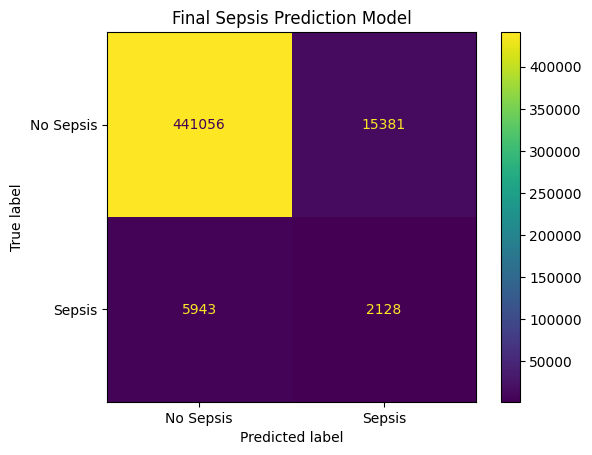

In [77]:
cm = confusion_matrix(y_test, y_test_pred_final)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Sepsis", "Sepsis"]
).plot(values_format="d")

plt.title("Final Sepsis Prediction Model")
plt.show()

## Model Deployment

In [78]:
import joblib

joblib.dump(model_val, "sepsis_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [79]:
import joblib

joblib.dump(feature_columns, "sepsis_feature_columns.pkl")

print("Feature list saved successfully!")
print(feature_columns)

Feature list saved successfully!
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Glucose', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'Hour']


In [80]:
joblib.dump(final_threshold, "sepsis_threshold.pkl")

print("Threshold saved:", final_threshold)

Threshold saved: 0.8


In [81]:
import joblib
import os

print("Model file exists:", os.path.exists("sepsis_prediction_model.pkl"))
print("Feature file exists:", os.path.exists("sepsis_feature_columns.pkl"))
print("Threshold file exists:", os.path.exists("sepsis_threshold.pkl"))

Model file exists: True
Feature file exists: True
Threshold file exists: True


In [82]:
#%pip install streamlit

In [83]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.51.0


In [84]:
#%pip check

In [85]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd

# Load the saved model and settings
model = joblib.load("sepsis_prediction_model.pkl")
feature_columns = joblib.load("sepsis_feature_columns.pkl")
threshold = joblib.load("sepsis_threshold.pkl")

st.title("Sepsis Prediction System")
st.write("Educational demonstration using a trained LightGBM model.")
st.warning(
    "This tool is for academic demonstration only, "
    "not for medical diagnosis or treatment."
)

st.subheader("Enter Patient Measurements")

with st.form("prediction_form"):
    values = {}

    for feature in feature_columns:
        values[feature] = st.number_input(
            feature,
            value=0.0,
            format="%.2f"
        )

    submitted = st.form_submit_button("Predict")

if submitted:
    input_data = pd.DataFrame([values], columns=feature_columns)
    probability = model.predict_proba(input_data)[0][1]

    st.metric("Estimated model probability", f"{probability:.1%}")

    if probability >= threshold:
        st.error("Model prediction: Sepsis")
    else:
        st.success("Model prediction: No Sepsis")

Overwriting app.py


In [86]:
!streamlit run app.py

^C


In [87]:
import os

for file in [
    "app.py",
    "sepsis_prediction_model.pkl",
    "sepsis_feature_columns.pkl",
    "sepsis_threshold.pkl"
]:
    print(file, "->", os.path.exists(file))

app.py -> True
sepsis_prediction_model.pkl -> True
sepsis_feature_columns.pkl -> True
sepsis_threshold.pkl -> True


In [88]:
import subprocess
import time

process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.headless", "true"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(5)

print("Streamlit process running:", process.poll() is None)
print("Open this URL: http://localhost:8501")

Streamlit process running: True
Open this URL: http://localhost:8501


In [89]:
sample = X_test.iloc[0]

print(sample)
print("\nActual Sepsis Label:", y_test.iloc[0])

HR              83.50
O2Sat           98.00
Temp            37.00
SBP            121.00
MAP             80.00
DBP             62.00
Resp            18.00
Glucose        127.00
Age             85.57
Gender           0.00
Unit1            1.00
Unit2            0.00
HospAdmTime     -0.03
ICULOS           1.00
Hour             0.00
Name: 59, dtype: float64

Actual Sepsis Label: 0
